# Step 4 - Analyze Liquidity Migration During Roll Periods

Describe how outright volume, open interest, and calendar-spread activity change around FND using the panel from `02_clean_features.ipynb`. Results are descriptive for the available sample; they are not forecasts or cost savings.

This notebook also measures **how sharp the crossover is**, separately for volume and open interest, using existing local data only.

**Time convention:** the upstream `bdays_to_fnd` column counts observed UTC daily bars, including Sundays. Here it is an inherited **UTC panel observation index**, not a verified CME session calendar. Widths are observation intervals, not calendar days or intraday durations. Session reconstruction belongs upstream; this notebook does not silently change that convention.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

root = next((p for p in (Path.cwd(), Path.cwd().parent)
             if (p / 'data/processed/zn_roll_panel.parquet').exists()), None)
if root is None:
    raise FileNotFoundError('Run notebook 02 first; the roll panel is missing.')
input_path = root / 'data/processed/zn_roll_panel.parquet'
try:
    panel = pd.read_parquet(input_path)
except OSError as exc:
    # Compatibility fallback for older PyArrow; input files are not rewritten.
    if 'Repetition level histogram size mismatch' not in str(exc):
        raise
    panel = pd.read_parquet(input_path, engine='fastparquet')
required = {'roll_id', 'date', 'bdays_to_fnd', 'next_volume_share', 'next_oi_share', 'spread_volume'}
missing = required - set(panel.columns)
if missing:
    raise ValueError(f'Missing panel columns: {sorted(missing)}')
if panel.empty or panel[['roll_id', 'date', 'bdays_to_fnd']].isna().any().any():
    raise ValueError('Panel must contain nonmissing roll/date/index identifiers.')
panel['date'] = pd.to_datetime(panel['date'])
panel = panel.sort_values(['roll_id', 'date']).copy()
if panel.duplicated(['roll_id', 'date']).any():
    raise ValueError('Duplicate roll/date observations.')
for roll_id, grp in panel.groupby('roll_id'):
    days = grp.bdays_to_fnd.to_numpy(dtype=float)
    if not np.isfinite(days).all() or (days != np.floor(days)).any() or (np.diff(days) <= 0).any():
        raise ValueError(f'Invalid or non-increasing panel index: {roll_id}')
for col in ['next_volume_share', 'next_oi_share']:
    if not panel[col].dropna().between(0, 1).all():
        raise ValueError(f'{col} must be missing or in [0, 1].')
output_dir = root / 'results/liquidity_migration'
output_dir.mkdir(parents=True, exist_ok=True)
print(f'{panel.roll_id.nunique()} rolls | {len(panel):,} daily observations')
print(f'UTC Sunday rows: {(panel.date.dt.dayofweek == 6).sum()}')
print(f'Panel index relative to FND: {panel.bdays_to_fnd.min()} to {panel.bdays_to_fnd.max()}')
panel.head()


27 rolls | 837 daily observations
UTC Sunday rows: 140
Panel index relative to FND: -25 to 5
Out[1]: 
      roll_id front  next  ...   total_oi  next_oi_share  spread_volume
0  ZNH0->ZNM0  ZNH0  ZNM0  ...  3902950.0       0.025428          29640
1  ZNH0->ZNM0  ZNH0  ZNM0  ...  3953130.0       0.030530          27875
2  ZNH0->ZNM0  ZNH0  ZNM0  ...  4031276.0       0.035261            101
3  ZNH0->ZNM0  ZNH0  ZNM0  ...  4021712.0       0.035345          13305
4  ZNH0->ZNM0  ZNH0  ZNM0  ...  4061736.0       0.037490          10403

[5 rows x 14 columns]


## 1. Cross-roll migration curves

Lines show the median share across rolls; shaded areas show the 25th to 75th percentiles.

Out[2]: 
    bdays_to_fnd  volume_median  volume_q25  ...    oi_q25    oi_q75  rolls
0            -25       0.000546    0.000258  ...  0.003715  0.005817     27
1            -24       0.000596    0.000413  ...  0.004140  0.005871     27
2            -23       0.000968    0.000505  ...  0.004703  0.007083     27
3            -22       0.001018    0.000609  ...  0.005349  0.008006     27
4            -21       0.001083    0.000741  ...  0.005999  0.009777     27
5            -20       0.001520    0.001294  ...  0.006701  0.010661     27
6            -19       0.001607    0.001110  ...  0.007458  0.011541     27
7            -18       0.001642    0.001188  ...  0.007756  0.012994     27
8            -17       0.003335    0.001579  ...  0.009216  0.015933     27
9            -16       0.002598    0.002157  ...  0.009929  0.018295     27
10           -15       0.003415    0.002056  ...  0.010622  0.022195     27
11           -14       0.003952    0.003147  ...  0.012505  0.022284     27
12 

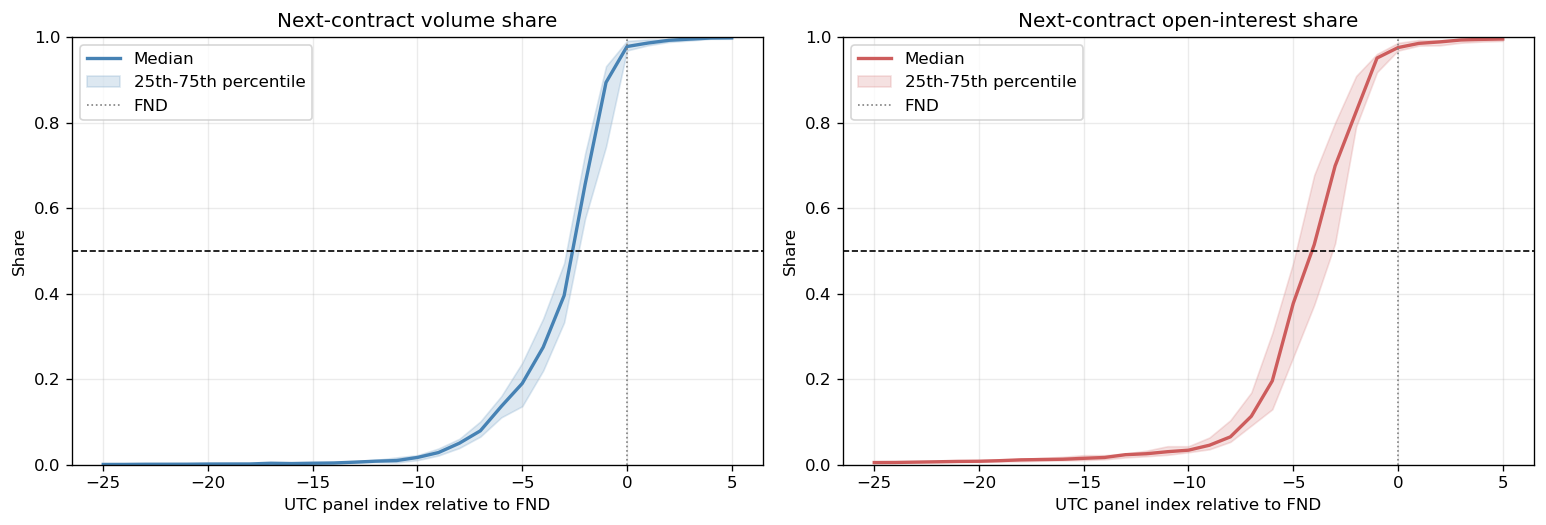

In [2]:
curve = (panel.groupby('bdays_to_fnd')
    .agg(volume_median=('next_volume_share', 'median'),
         volume_q25=('next_volume_share', lambda x: x.quantile(0.25)),
         volume_q75=('next_volume_share', lambda x: x.quantile(0.75)),
         oi_median=('next_oi_share', 'median'),
         oi_q25=('next_oi_share', lambda x: x.quantile(0.25)),
         oi_q75=('next_oi_share', lambda x: x.quantile(0.75)),
         rolls=('roll_id', 'nunique')).reset_index().sort_values('bdays_to_fnd'))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for ax, key, title, color in [
    (axes[0], 'volume', 'Next-contract volume share', 'steelblue'),
    (axes[1], 'oi', 'Next-contract open-interest share', 'indianred')]:
    ax.plot(curve['bdays_to_fnd'], curve[f'{key}_median'], color=color, lw=2, label='Median')
    ax.fill_between(curve['bdays_to_fnd'], curve[f'{key}_q25'], curve[f'{key}_q75'], color=color, alpha=0.18, label='25th-75th percentile')
    ax.axhline(0.5, color='black', ls='--', lw=1)
    ax.axvline(0, color='gray', ls=':', lw=1, label='FND')
    ax.set(title=title, xlabel='UTC panel index relative to FND', ylabel='Share', ylim=(0, 1))
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()
curve

## 2. Calendar-spread activity

Spread volume is normalized within each roll by that roll's maximum in the panel window. This compares when spread activity occurs without treating spread and outright volume as interchangeable units.

Out[3]: 
    bdays_to_fnd    median       q25       q75
0            -25  0.000819  0.000366  0.001871
1            -24  0.001388  0.000556  0.002809
2            -23  0.000958  0.000034  0.002196
3            -22  0.001509  0.000814  0.002778
4            -21  0.001348  0.000631  0.002038
5            -20  0.001330  0.000630  0.003751
6            -19  0.001676  0.000906  0.003311
7            -18  0.002987  0.001346  0.004547
8            -17  0.001311  0.000007  0.004510
9            -16  0.002526  0.001477  0.009008
10           -15  0.003277  0.001883  0.007841
11           -14  0.008550  0.004066  0.012388
12           -13  0.007294  0.003447  0.013686
13           -12  0.009492  0.008712  0.019105
14           -11  0.007650  0.000225  0.020878
15           -10  0.031090  0.013808  0.059656
16            -9  0.036534  0.025807  0.095325
17            -8  0.134535  0.047342  0.211042
18            -7  0.222681  0.043096  0.562729
19            -6  0.587684  0.366924  0.765005
20  

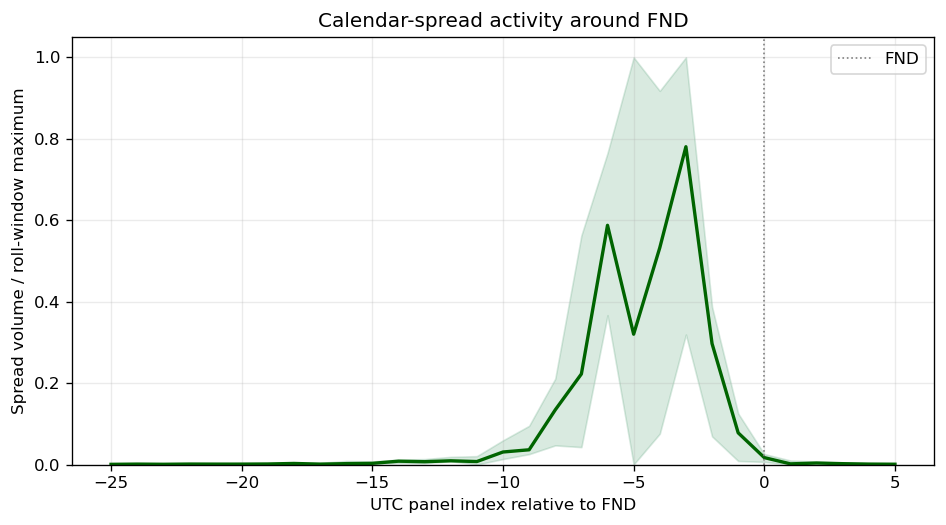

In [3]:
panel['spread_volume_index'] = panel.groupby('roll_id')['spread_volume'].transform(
    lambda x: x / x.max() if x.max() > 0 else np.nan)
spread_curve = (panel.groupby('bdays_to_fnd')['spread_volume_index']
    .agg(median='median', q25=lambda x: x.quantile(0.25), q75=lambda x: x.quantile(0.75)).reset_index())
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(spread_curve['bdays_to_fnd'], spread_curve['median'], color='darkgreen', lw=2)
ax.fill_between(spread_curve['bdays_to_fnd'], spread_curve['q25'], spread_curve['q75'], color='seagreen', alpha=0.18)
ax.axvline(0, color='gray', ls=':', lw=1, label='FND')
ax.set(title='Calendar-spread activity around FND', xlabel='UTC panel index relative to FND', ylabel='Spread volume / roll-window maximum', ylim=(0, 1.05))
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()
spread_curve

## 3. Roll-level crossover timing

For this descriptive table, crossover means the first observed share strictly above 50%. The next notebook formalizes the event definition and produces the target table.

Column names retain `bdays_to_fnd` for compatibility; values use the UTC panel index described above.

In [4]:
roll_summary = []
for roll_id, grp in panel.groupby('roll_id'):
    grp = grp.sort_values('bdays_to_fnd')
    vol_hits = grp.loc[grp['next_volume_share'] > 0.5]
    oi_hits = grp.loc[grp['next_oi_share'] > 0.5]
    roll_summary.append({
        'roll_id': roll_id,
        'volume_crossover_bdays_to_fnd': vol_hits.iloc[0]['bdays_to_fnd'] if len(vol_hits) else np.nan,
        'oi_crossover_bdays_to_fnd': oi_hits.iloc[0]['bdays_to_fnd'] if len(oi_hits) else np.nan,
        'max_spread_volume': grp['spread_volume'].max(),
    })
roll_summary = pd.DataFrame(roll_summary).sort_values('roll_id')
display(roll_summary)
print('Median volume-crossover timing:', roll_summary['volume_crossover_bdays_to_fnd'].median())
print('Rolls with OI crossover:', roll_summary['oi_crossover_bdays_to_fnd'].notna().sum(), '/', len(roll_summary))

Median volume-crossover timing: -2.0
Rolls with OI crossover: 27 / 27


,roll_id,volume_crossover_bdays_to_fnd,oi_crossover_bdays_to_fnd,max_spread_volume
0,ZNH0->ZNM0,-1,-2,2181870
1,ZNH1->ZNM1,-1,-2,2400665
2,ZNH2->ZNM2,-2,-3,2219653
3,ZNH3->ZNM3,-2,-4,2474634
4,ZNH4->ZNM4,-1,-4,3894122
5,ZNH5->ZNM5,-2,-3,3524683
6,ZNH6->ZNM6,-2,-2,4084999
7,ZNM0->ZNU0,-1,-2,2390678
8,ZNM1->ZNU1,-3,-4,2896100
9,ZNM2->ZNU2,-3,-4,2109845


## 4. How sharp is the crossover? Definitions and coverage

Analyze each roll's volume and OI shares separately:

- **Crossover:** first observed share strictly **greater than 50%**, consistent with notebook 05. Exactly 50% does not cross.
- **First-passage width:** panel index of first share **at least** the upper threshold minus index of first share **at least** the lower threshold. Report 10%-90%, 20%-80%, and 40%-60%. These describe first passages, not fitted monotonic curves or sustained threshold occupancy.
- **Crossing jump:** share at crossover minus share at the immediately preceding panel observation, in **percentage points**. Missing shares or index gaps make the jump unavailable.
- **Reversion:** any later observed share at or below 50%. Follow-up coverage matters: no observed reversion does not prove permanence.

A width is unavailable if the lower threshold is already exceeded at the first valid observation (left censoring), the upper threshold is not observed, or the interval from the lower threshold's preceding observation through the upper hit contains missing shares or index gaps. Status columns explain exclusions. Width **zero** means both thresholds were first exceeded in the same daily bar, not instantaneous migration.

Retain rolls without an observed crossover. This is realized-path description, never a predictor.

In [5]:
WIDTHS = [('width_10_90', .10, .90), ('width_20_80', .20, .80), ('width_40_60', .40, .60)]


def first_passage_width(shares, days, lower, upper):
    valid = np.flatnonzero(np.isfinite(shares))
    if not len(valid):
        return np.nan, 'no_valid_shares'
    lo_hits = np.flatnonzero(shares >= lower)
    if not len(lo_hits):
        return np.nan, 'lower_not_observed'
    lo = int(lo_hits[0])
    if lo == valid[0]:
        return np.nan, 'left_censored'
    hi_hits = np.flatnonzero(shares >= upper)
    if not len(hi_hits):
        return np.nan, 'upper_not_observed'
    hi = int(hi_hits[0])
    if not np.isfinite(shares[lo-1:hi+1]).all():
        return np.nan, 'missing_share_in_interval'
    if not (np.diff(days[lo-1:hi+1]) == 1).all():
        return np.nan, 'panel_gap_in_interval'
    return float(days[hi] - days[lo]), 'observed'


def measure_sharpness(frame):
    records, aligned = [], []
    for roll_id, grp in frame.groupby('roll_id', sort=True):
        grp = grp.sort_values('date').reset_index(drop=True)
        days = grp.bdays_to_fnd.to_numpy(dtype=float)
        for measure in ['volume', 'oi']:
            shares = grp[f'next_{measure}_share'].to_numpy(dtype=float)
            hits = np.flatnonzero(shares > .50)
            valid = np.flatnonzero(np.isfinite(shares))
            row = dict(roll_id=roll_id, measure=measure,
                valid_share_observations=int(np.isfinite(shares).sum()),
                missing_share_observations=int(np.isnan(shares).sum()),
                crossover_observed=bool(len(hits)), crossover_left_censored=False,
                crossover_date=pd.NaT, crossover_panel_index=np.nan, crossing_jump_pp=np.nan,
                followup_observations=0, followup_missing_shares=0, followup_index_gaps=0,
                reversion_observations=np.nan, has_observed_reversion=np.nan)
            for name, lower, upper in WIDTHS:
                row[name], row[name+'_status'] = first_passage_width(shares, days, lower, upper)
            if len(hits):
                i = int(hits[0])
                row.update(crossover_date=grp.loc[i, 'date'], crossover_panel_index=days[i],
                           crossover_left_censored=bool(i == valid[0]))
                if i > 0 and np.isfinite(shares[i-1]) and days[i] - days[i-1] == 1:
                    row['crossing_jump_pp'] = float(100 * (shares[i] - shares[i-1]))
                followup = shares[i+1:]
                row['followup_observations'] = int(np.isfinite(followup).sum())
                row['followup_missing_shares'] = int(np.isnan(followup).sum())
                row['followup_index_gaps'] = int((np.diff(days[i:]) != 1).sum())
                if row['followup_observations']:
                    row['reversion_observations'] = int((followup <= .50).sum())
                    row['has_observed_reversion'] = bool(row['reversion_observations'])
                if not row['crossover_left_censored']:
                    aligned.append(pd.DataFrame({'roll_id':roll_id, 'measure':measure,
                                                  'offset':days-days[i], 'share':shares}))
            records.append(row)
    aligned_frame = (pd.concat(aligned, ignore_index=True) if aligned else
                     pd.DataFrame(columns=['roll_id', 'measure', 'offset', 'share']))
    return pd.DataFrame(records), aligned_frame


sharpness, aligned_shares = measure_sharpness(panel)
display(sharpness[['roll_id', 'measure', 'crossover_date', 'crossover_panel_index',
    'width_10_90', 'width_20_80', 'width_40_60', 'crossing_jump_pp',
    'followup_observations', 'reversion_observations']])

,roll_id,measure,crossover_date,crossover_panel_index,width_10_90,width_20_80,width_40_60,crossing_jump_pp,followup_observations,reversion_observations
0,ZNH0->ZNM0,volume,2020-02-27,-1.0,4.0,3.0,1.0,17.999875,6,0
1,ZNH0->ZNM0,oi,2020-02-26,-2.0,NaN,4.0,1.0,27.925776,6,0
2,ZNH1->ZNM1,volume,2021-02-25,-1.0,4.0,2.0,0.0,35.083996,6,0
3,ZNH1->ZNM1,oi,2021-02-24,-2.0,5.0,2.0,0.0,34.448268,7,0
4,ZNH2->ZNM2,volume,2022-02-25,-2.0,4.0,3.0,1.0,35.001746,7,0
5,ZNH2->ZNM2,oi,2022-02-24,-3.0,NaN,2.0,0.0,31.316402,8,0
6,ZNH3->ZNM3,volume,2023-02-26,-2.0,6.0,4.0,2.0,12.503123,7,0
7,ZNH3->ZNM3,oi,2023-02-23,-4.0,NaN,1.0,1.0,34.145092,8,0
8,ZNH4->ZNM4,volume,2024-02-28,-1.0,6.0,2.0,1.0,37.151331,6,0
9,ZNH4->ZNM4,oi,2024-02-25,-4.0,5.0,3.0,2.0,21.243296,9,0


## 5. Cross-roll summaries and exceptional cases

Each roll has equal weight. Counts are metric-specific: unavailable widths are excluded, never filled with zero. Status counts show exclusions. Reversion counts use only rolls with an observed crossover and at least one later nonmissing share; coverage columns expose incomplete follow-up.

In [6]:
metric_columns = [name for name, _, _ in WIDTHS] + ['crossing_jump_pp']
long_metrics = sharpness.melt(id_vars=['roll_id', 'measure'], value_vars=metric_columns,
                              var_name='metric', value_name='value')
sharpness_summary = (long_metrics.groupby(['measure', 'metric'])['value']
    .agg(valid_rolls='count', median='median', q25=lambda s:s.quantile(.25),
         q75=lambda s:s.quantile(.75), minimum='min', maximum='max').reset_index())
sharpness_summary['total_rolls'] = sharpness_summary.measure.map(sharpness.groupby('measure').size())
sharpness_summary['unit'] = np.where(sharpness_summary.metric == 'crossing_jump_pp',
                                     'percentage points', 'UTC panel observation intervals')
width_status_counts = (sharpness.melt(id_vars=['roll_id', 'measure'],
    value_vars=[name+'_status' for name, _, _ in WIDTHS], var_name='metric', value_name='status')
    .groupby(['measure', 'metric', 'status']).size().rename('rolls').reset_index())
coverage_rows = []
for measure, grp in sharpness.groupby('measure'):
    eligible = grp.loc[grp.crossover_observed & (grp.followup_observations > 0)]
    coverage_rows.append(dict(measure=measure, total_rolls=len(grp),
        observed_crossovers=int(grp.crossover_observed.sum()),
        left_censored_crossovers=int(grp.crossover_left_censored.sum()),
        rolls_with_followup=len(eligible),
        rolls_with_observed_reversion=int(eligible.has_observed_reversion.sum()),
        rolls_with_incomplete_followup=int(((eligible.followup_missing_shares > 0) |
                                           (eligible.followup_index_gaps > 0)).sum()),
        minimum_followup_observations=eligible.followup_observations.min()))
reversion_summary = pd.DataFrame(coverage_rows)
display(sharpness_summary)
display(width_status_counts)
display(reversion_summary)
print('Widest observed 20%-80% transitions (up to 3 per measure):')
display(sharpness.dropna(subset=['width_20_80']).sort_values('width_20_80', ascending=False)
        .groupby('measure', sort=False).head(3)[['roll_id', 'measure', 'width_20_80', 'crossing_jump_pp']])

Widest observed 20%-80% transitions (up to 3 per measure):


,measure,metric,valid_rolls,median,q25,q75,minimum,maximum,total_rolls,unit
0,oi,crossing_jump_pp,27,27.925776,22.120501,30.542275,1.101425,37.342070,27,percentage points
1,oi,width_10_90,19,6.000000,5.000000,6.000000,3.000000,7.000000,27,UTC panel observation intervals
2,oi,width_20_80,22,3.000000,2.000000,4.000000,1.000000,6.000000,27,UTC panel observation intervals
3,oi,width_40_60,24,1.000000,0.750000,1.000000,0.000000,2.000000,27,UTC panel observation intervals
4,volume,crossing_jump_pp,27,25.465948,22.915390,31.658173,7.800963,40.666663,27,percentage points
5,volume,width_10_90,27,6.000000,4.500000,6.000000,3.000000,7.000000,27,UTC panel observation intervals
6,volume,width_20_80,27,3.000000,3.000000,4.000000,2.000000,6.000000,27,UTC panel observation intervals
7,volume,width_40_60,27,1.000000,0.000000,1.000000,0.000000,2.000000,27,UTC panel observation intervals


,measure,metric,status,rolls
0,oi,width_10_90_status,missing_share_in_interval,8
1,oi,width_10_90_status,observed,19
2,oi,width_20_80_status,missing_share_in_interval,5
3,oi,width_20_80_status,observed,22
4,oi,width_40_60_status,missing_share_in_interval,3
5,oi,width_40_60_status,observed,24
6,volume,width_10_90_status,observed,27
7,volume,width_20_80_status,observed,27
8,volume,width_40_60_status,observed,27


,measure,total_rolls,observed_crossovers,left_censored_crossovers,rolls_with_followup,rolls_with_observed_reversion,rolls_with_incomplete_followup,minimum_followup_observations
0,oi,27,27,0,27,0,12,6
1,volume,27,27,0,27,0,0,6


,roll_id,measure,width_20_80,crossing_jump_pp
46,ZNZ2->ZNH3,volume,6.0,25.465948
49,ZNZ3->ZNH4,oi,6.0,1.101425
47,ZNZ2->ZNH3,oi,5.0,24.208729
44,ZNZ1->ZNH2,volume,5.0,22.521363
40,ZNU6->ZNZ6,volume,5.0,37.690380
37,ZNU4->ZNZ4,oi,5.0,21.175739


## 6. Event-aligned migration and width distribution

Align each roll to its own first share above 50%; volume and OI use their **own** crossover dates. This isolates transition shape from calendar timing differences. It cannot compare absolute timing of volume versus OI or serve as an ex-ante signal. Thin lines show individual rolls; thick lines and bands show medians and interquartile ranges. The exported curve table includes nonmissing contributing roll counts at every offset. Left-censored crossovers are excluded from these curves.

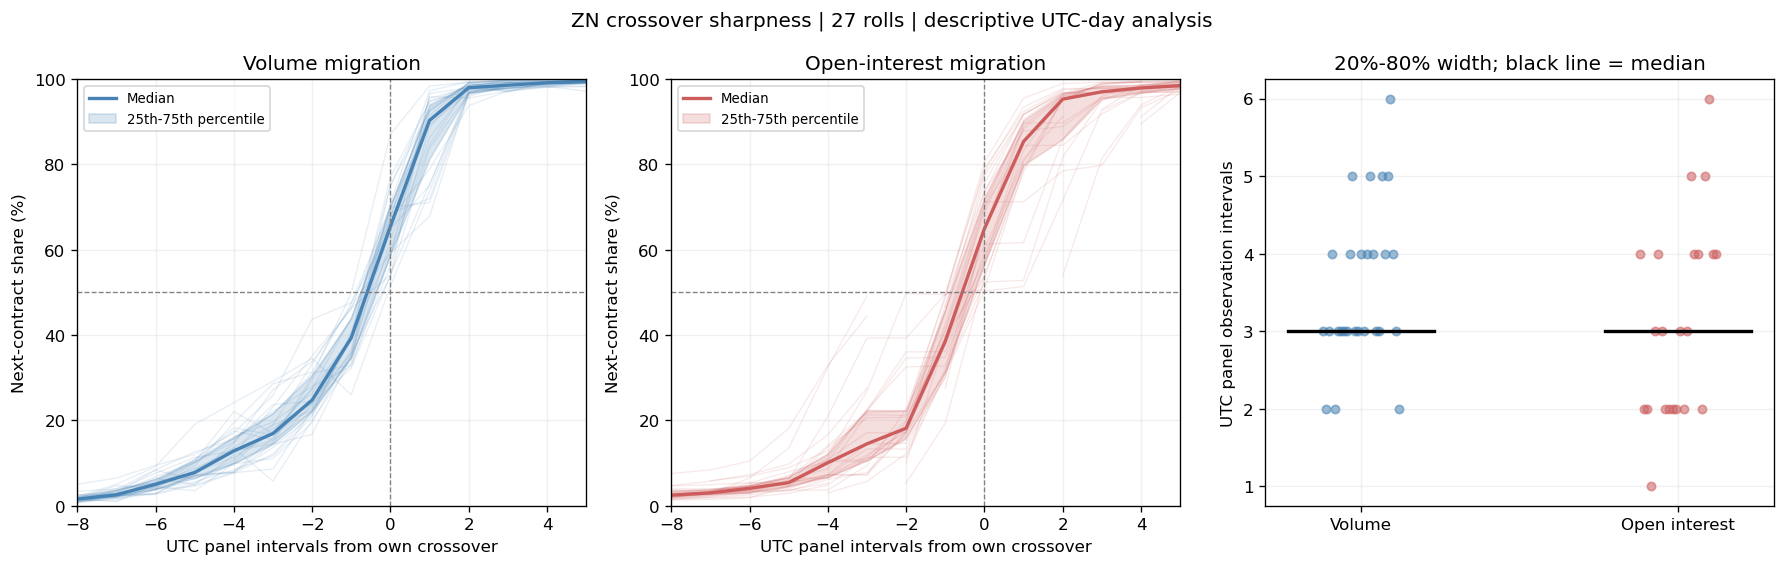

In [7]:
curve_rows = []
for (measure, offset), grp in aligned_shares.groupby(['measure', 'offset']):
    values = grp['share'].dropna()
    curve_rows.append(dict(measure=measure, offset=offset, contributing_rolls=len(values),
        median=values.median(), q25=values.quantile(.25), q75=values.quantile(.75)))
aligned_curve = pd.DataFrame(curve_rows, columns=['measure', 'offset', 'contributing_rolls', 'median', 'q25', 'q75'])
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
colors = {'volume':'steelblue', 'oi':'indianred'}
for measure, ax in zip(['volume', 'oi'], axes[:2]):
    paths = aligned_shares.loc[aligned_shares.measure == measure]
    for _, grp in paths.groupby('roll_id'):
        ax.plot(grp.offset, grp.share*100, color=colors[measure], alpha=.13, lw=.8)
    curve = aligned_curve.loc[aligned_curve.measure == measure].sort_values('offset')
    if not curve.empty:
        ax.plot(curve.offset, curve['median']*100, color=colors[measure], lw=2, label='Median')
        ax.fill_between(curve.offset, curve.q25*100, curve.q75*100,
                        color=colors[measure], alpha=.2, label='25th-75th percentile')
        ax.legend(fontsize=8)
    else:
        ax.text(.5, .5, 'No uncensored crossover observed', transform=ax.transAxes, ha='center')
    ax.axhline(50, color='gray', ls='--', lw=.8)
    ax.axvline(0, color='gray', ls='--', lw=.8)
    ax.set(title='Volume migration' if measure == 'volume' else 'Open-interest migration',
        xlim=(-8, 5), ylim=(0, 100), xlabel='UTC panel intervals from own crossover', ylabel='Next-contract share (%)')
for j, measure in enumerate(['volume', 'oi']):
    values = sharpness.loc[sharpness.measure == measure, 'width_20_80'].dropna()
    if len(values):
        axes[2].scatter(j+np.linspace(-.12, .12, len(values)), values, color=colors[measure], alpha=.55, s=25)
        axes[2].plot([j-.23, j+.23], [values.median()]*2, color='black', lw=2)
axes[2].set(xticks=[0, 1], xticklabels=['Volume', 'Open interest'],
    title='20%-80% width; black line = median', ylabel='UTC panel observation intervals')
for ax in axes:
    ax.grid(alpha=.18)
fig.suptitle(f'ZN crossover sharpness | {panel.roll_id.nunique()} rolls | descriptive UTC-day analysis')
fig.tight_layout()
fig.savefig(output_dir / 'crossover_sharpness.png', dpi=180, bbox_inches='tight')
plt.show()

## 7. Interpretation and saved outputs

Read width together with the crossing jump and reversion coverage. Tight timing relative to FND is different from a steep transition. Daily bars cannot locate the transition within a day; missing observations limit precision, especially for OI. These results describe volume/OI migration, not order-size-specific execution costs.

The following summary is computed from the current input, not hard-coded. CSV tables and the figure are saved under `results/liquidity_migration/`; upstream panels and target definitions are unchanged.

The gap-aware width exclusions can change medians relative to exploratory calculations that span missing shares, particularly for OI. Compare each estimate together with its valid-roll count and status table.

In [8]:
for measure in ['volume', 'oi']:
    grp = sharpness.loc[sharpness.measure == measure]
    print(f'\n{measure.upper()} ({len(grp)} rolls)')
    for name, lower, upper in WIDTHS:
        values = grp[name].dropna()
        if len(values):
            print(f'  {lower:.0%}-{upper:.0%}: median {values.median():g}, '
                f'IQR {values.quantile(.25):g}-{values.quantile(.75):g} UTC panel intervals '
                f'({len(values)}/{len(grp)} valid rolls; {(values == 0).sum()} same-bar widths)')
        else:
            print(f'  {name}: no fully observed widths')
    jumps = grp.crossing_jump_pp.dropna()
    if len(jumps):
        print(f'  Crossing jump median: {jumps.median():.2f} percentage points ({len(jumps)} valid rolls)')
    eligible = grp.loc[grp.crossover_observed & (grp.followup_observations > 0)]
    print(f'  Observed post-crossing reversion: {int(eligible.has_observed_reversion.sum())}/{len(eligible)} '
          'rolls with follow-up, within the available window only')
for name, table in [
    ('crossover_sharpness_by_roll', sharpness), ('crossover_sharpness_summary', sharpness_summary),
    ('crossover_width_status', width_status_counts), ('crossover_reversion_coverage', reversion_summary),
    ('crossover_aligned_curve', aligned_curve),
]:
    table.to_csv(output_dir / f'{name}.csv', index=False)
print(f'\nSaved tables and crossover_sharpness.png to {output_dir}')


VOLUME (27 rolls)
  10%-90%: median 6, IQR 4.5-6 UTC panel intervals (27/27 valid rolls; 0 same-bar widths)
  20%-80%: median 3, IQR 3-4 UTC panel intervals (27/27 valid rolls; 0 same-bar widths)
  40%-60%: median 1, IQR 0-1 UTC panel intervals (27/27 valid rolls; 10 same-bar widths)
  Crossing jump median: 25.47 percentage points (27 valid rolls)
  Observed post-crossing reversion: 0/27 rolls with follow-up, within the available window only

OI (27 rolls)
  10%-90%: median 6, IQR 5-6 UTC panel intervals (19/27 valid rolls; 0 same-bar widths)
  20%-80%: median 3, IQR 2-4 UTC panel intervals (22/27 valid rolls; 0 same-bar widths)
  40%-60%: median 1, IQR 0.75-1 UTC panel intervals (24/27 valid rolls; 6 same-bar widths)
  Crossing jump median: 27.93 percentage points (27 valid rolls)
  Observed post-crossing reversion: 0/27 rolls with follow-up, within the available window only

Saved tables and crossover_sharpness.png to C:\Users\84324\Desktop\futures-project\results\liquidity_migratio